<a href="https://colab.research.google.com/github/Janani-Hendeniya/EN3160_Assignment_03/blob/main/230238R_A03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 - Assignment 03: Neural Networks

**Name:** Hendeniya H.M.J.C.  
**Index Number:** 230238R  
**University:** University of Moratuwa  
**Module:** EN3160

**GitHub Repository:** https://github.com/Janani-Hendeniya/EN3160_Assignment_03

---

## Assignment Overview

This notebook implements and compares neural network
architectures through three experiments:

1. A manually implemented two-layer neural network on CIFAR-10.
2. LeNet-5 and a modern CNN on MNIST.
3. ResNet18 transfer learning on the Hymenoptera dataset.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
from torchvision import datasets, transforms, models

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import copy
import time

from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cu130
Device: cuda


## Question 1: Manual Two-Layer Neural Network

The original single-layer dense network is extended with
a hidden layer of 100 sigmoid neurons.

Categorical cross-entropy is used as the loss function.
Forward propagation, gradient computation, and parameter
updates are performed manually without autograd.

In [6]:
# Question 1 - CIFAR-10 dataset

cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

cifar_train = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=cifar_transform
)

cifar_test = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=cifar_transform
)

cifar_train_loader = DataLoader(
    cifar_train, batch_size=256, shuffle=True, num_workers=2
)

cifar_test_loader = DataLoader(
    cifar_test, batch_size=256, shuffle=False, num_workers=2
)

print("Training images:", len(cifar_train))
print("Test images:", len(cifar_test))
print("Classes:", cifar_train.classes)

100%|██████████| 170M/170M [51:33<00:00, 55.1kB/s]


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [7]:
#3.3 Initialize weights and biases
# Network architecture
Din = 3 * 32 * 32
H = 100
K = 10

# Initialize parameters
W1 = (torch.randn(Din, H, device=device)
      * np.sqrt(1.0 / Din))
b1 = torch.zeros(H, device=device)

W2 = (torch.randn(H, K, device=device)
      * np.sqrt(1.0 / H))
b2 = torch.zeros(K, device=device)

# Training hyperparameters
epochs_q1 = 10
lr = 0.1

q1_history = {
    "train_loss": [],
    "train_acc": [],
    "test_acc": []
}

print("W1 shape:", W1.shape)
print("W2 shape:", W2.shape)

W1 shape: torch.Size([3072, 100])
W2 shape: torch.Size([100, 10])


In [8]:
#3.4 Defining a function for accuracy
def evaluate_manual_network(data_loader):
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            x = images.reshape(images.shape[0], -1)

            # Manual forward pass
            z1 = x @ W1 + b1
            a1 = torch.sigmoid(z1)
            logits = a1 @ W2 + b2

            predictions = torch.argmax(logits, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

In [9]:
#3.5 Implement manual training and backpropagation
for epoch in range(epochs_q1):

    running_loss = 0.0

    for images, labels in cifar_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        N = images.shape[0]
        x = images.reshape(N, -1)

        # -----------------------------
        # 1. Forward propagation
        # -----------------------------

        z1 = x @ W1 + b1
        a1 = torch.sigmoid(z1)

        logits = a1 @ W2 + b2

        # Softmax probabilities
        probabilities = torch.softmax(logits, dim=1)

        # Cross-entropy loss
        loss = -torch.log(
            probabilities[
                torch.arange(N, device=device),
                labels
            ].clamp(min=1e-12)
        ).mean()

        running_loss += loss.item()

        # -----------------------------
        # 2. Manual backpropagation
        # -----------------------------

        # Gradient of cross-entropy + softmax
        dlogits = probabilities.clone()
        dlogits[
            torch.arange(N, device=device), labels
        ] -= 1
        dlogits /= N

        # Gradients for output layer
        dW2 = a1.T @ dlogits
        db2 = dlogits.sum(dim=0)

        # Gradient through hidden layer
        da1 = dlogits @ W2.T

        # Derivative of sigmoid: a(1-a)
        dz1 = da1 * a1 * (1 - a1)

        # Gradients for first layer
        dW1 = x.T @ dz1
        db1 = dz1.sum(dim=0)

        # -----------------------------
        # 3. Parameter updates
        # -----------------------------

        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

    avg_loss = running_loss / len(cifar_train_loader)

    train_acc = evaluate_manual_network(cifar_train_loader)
    test_acc = evaluate_manual_network(cifar_test_loader)

    q1_history["train_loss"].append(avg_loss)
    q1_history["train_acc"].append(train_acc)
    q1_history["test_acc"].append(test_acc)

    print(
        f"Epoch {epoch+1}/{epochs_q1} | "
        f"Loss: {avg_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch 1/10 | Loss: 1.9338 | Train Acc: 36.84% | Test Acc: 36.92%
Epoch 2/10 | Loss: 1.7902 | Train Acc: 38.87% | Test Acc: 38.77%
Epoch 3/10 | Loss: 1.7423 | Train Acc: 40.43% | Test Acc: 40.04%
Epoch 4/10 | Loss: 1.7124 | Train Acc: 41.17% | Test Acc: 40.98%
Epoch 5/10 | Loss: 1.6881 | Train Acc: 41.66% | Test Acc: 40.80%
Epoch 6/10 | Loss: 1.6674 | Train Acc: 42.58% | Test Acc: 41.89%
Epoch 7/10 | Loss: 1.6481 | Train Acc: 43.58% | Test Acc: 42.65%
Epoch 8/10 | Loss: 1.6331 | Train Acc: 43.82% | Test Acc: 42.65%
Epoch 9/10 | Loss: 1.6190 | Train Acc: 44.86% | Test Acc: 43.28%
Epoch 10/10 | Loss: 1.6043 | Train Acc: 45.00% | Test Acc: 43.48%


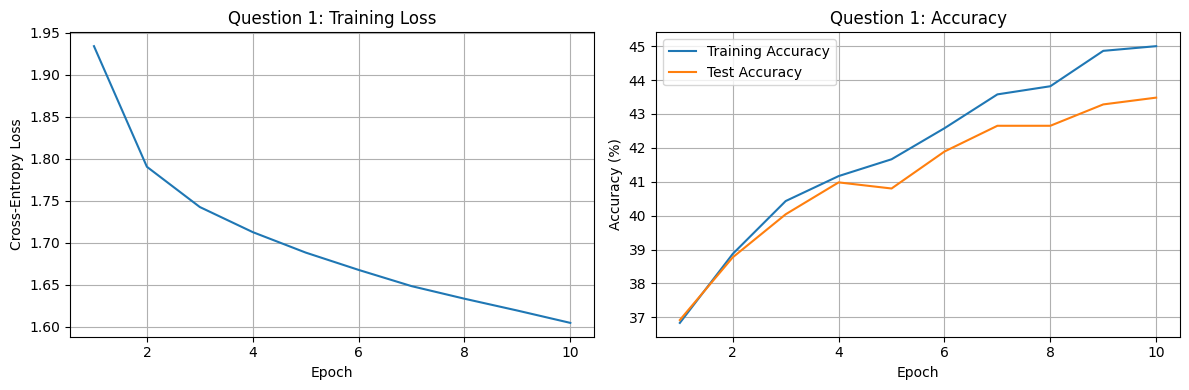

In [10]:
#3.6 Plot the results
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs_axis = range(1, epochs_q1 + 1)

axes[0].plot(epochs_axis, q1_history["train_loss"])
axes[0].set_title("Question 1: Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)

axes[1].plot(
    epochs_axis, q1_history["train_acc"],
    label="Training Accuracy"
)
axes[1].plot(
    epochs_axis, q1_history["test_acc"],
    label="Test Accuracy"
)
axes[1].set_title("Question 1: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Question 1: Results and Discussion

The manually implemented two-layer neural network was trained on the CIFAR-10 dataset for **10 epochs** using categorical cross-entropy loss and manual backpropagation. The network achieved a final **training accuracy of 45.00%** and a **test accuracy of 43.48%**.

The training loss decreased steadily from **1.9338 to 1.6043**, indicating that the network successfully learned from the training data. Both training and test accuracies generally improved throughout the 10 epochs, demonstrating gradual improvement in classification performance.

The difference between training and test accuracy was only **1.52 percentage points**, suggesting reasonable generalization with no strong evidence of overfitting. However, the relatively low accuracies indicate that the network still struggles to classify complex images accurately.

One major limitation is that the input images were flattened into one-dimensional vectors before processing. Consequently, the fully connected network does not explicitly preserve spatial relationships between neighbouring pixels, unlike convolutional neural networks (CNNs), which can learn spatial features more effectively.

Overall, the results demonstrate that the manually implemented network learns successfully, but its simple architecture limits its performance on CIFAR-10.